In [132]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression # 가장 많이 사용
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.preprocessing import PolynomialFeatures # 다항특성 자동완성
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.linear_model import Ridge # 릿지규제
from sklearn.linear_model import Lasso # 라쏘규제
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [133]:
df = pd.read_csv('data/MultipleLinearRegressionData.csv')
df.head(2)
data = df.iloc[:,:-2].values
label = df.iloc[:,-1].values
df['place'].value_counts()



place
Library    7
Cafe       7
Home       6
Name: count, dtype: int64

In [134]:
# 원핫 인코딩 작업 - 다중공선성 : 특정컬럼이 다른 컬럼에 많은 영향을 미칠때 한개의 값을 임의로 없앰.
from sklearn.preprocessing import OneHotEncoder
place=df['place'].to_numpy().reshape(-1,1) # 2차원 배열로 가져옴
encoder = OneHotEncoder(sparse_output=False,drop='first')
result = encoder.fit_transform(place)


In [135]:
# data + result 합치기
total_data = np.concatenate((data,result),axis=1) # axis =1은 가로로 합쳐라, 0은 세로로 합쳐라

In [136]:
# 데이터 변환 = float

In [137]:
# 학습데이터, 테스트데이터 분리
train_data,test_data,train_label,test_label = train_test_split(total_data,label,random_state=42)
test_data

array([[0.5, 3. , 1. , 0. ],
       [8.4, 1. , 1. , 0. ],
       [6.9, 4. , 1. , 0. ],
       [1.2, 4. , 0. , 1. ],
       [4.5, 5. , 1. , 0. ]])

In [138]:
# 특성추가
poly = PolynomialFeatures(degree=15,include_bias=False)
poly.fit(train_data)
train_poly = poly.transform(train_data)
test_poly = poly.transform(test_data)
test_data


array([[0.5, 3. , 1. , 0. ],
       [8.4, 1. , 1. , 0. ],
       [6.9, 4. , 1. , 0. ],
       [1.2, 4. , 0. , 1. ],
       [4.5, 5. , 1. , 0. ]])

In [139]:
# 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

#예측
predict = lr.predict(test_poly)

# 정확도 
s = lr.score(train_poly,train_label)
s1 = lr.score(test_poly,test_label)
s,s1


(0.8727433820996173, -31356.747978567804)

In [125]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_poly)
train_scaled = ss.transform(train_poly)
test_scaled = ss.transform(test_poly)
train_scaled

array([[-0.91587049, -1.03509834,  2.54950976, ...,  0.        ,
         0.        , -0.81649658],
       [ 0.2552426 , -1.03509834, -0.39223227, ...,  0.        ,
         0.        , -0.81649658],
       [-1.27621298, -1.03509834, -0.39223227, ...,  0.        ,
         0.        , -0.81649658],
       ...,
       [ 0.03002854,  1.03509834, -0.39223227, ...,  0.        ,
         0.        , -0.81649658],
       [ 0.43541384,  0.        , -0.39223227, ...,  0.        ,
         0.        ,  1.22474487],
       [-0.60057081, -1.03509834, -0.39223227, ...,  0.        ,
         0.        ,  1.22474487]], shape=(15, 3875))

In [126]:
# 규제 작업
alpha_list = [0.001,0.01,0.1,1,10,100]
s_list =[]
s2_list =[]

for a in alpha_list:
    ridge = Ridge(alpha=a)
    ridge.fit(train_scaled,train_label)

    score = ridge.score(train_scaled,train_label)
    score2 = ridge.score(test_scaled,test_label)
    s_list.append(score)
    s2_list.append(score2)
s_list,s2_list

([0.9999998048473284,
  0.9999827085301521,
  0.9992426411873856,
  0.9888143977643786,
  0.8966296749641579,
  0.7266804521741648],
 [-2649342.301136918,
  -2635161.5764135774,
  -2705629.173215917,
  -5243449.273712431,
  -27036916.495872423,
  -63671469.95147198])

Text(0.5, 0, '리스트')

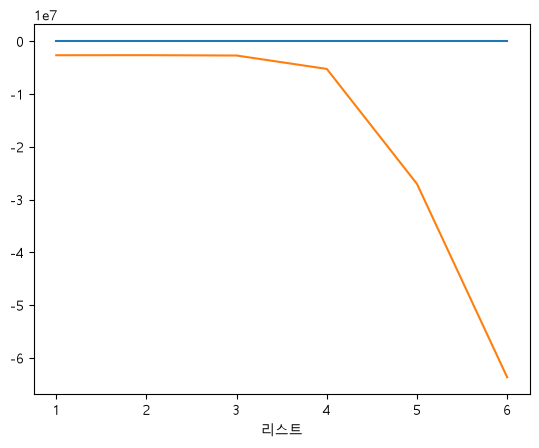

In [127]:
list = [1,2,3,4,5,6]

plt.plot(list,s_list)
plt.plot(list,s2_list)
plt.xlabel('리스트')

In [128]:
# 데이터 학습
ridge =Ridge(alpha=1)
ridge.fit(train_scaled,train_label)

# 데이터 예측
predict = ridge.predict(test_scaled)

# 정확도
scor = ridge.score(train_scaled,train_label)
scor2 = ridge.score(test_scaled,test_label)
scor,scor2

(0.9888143977643786, -5243449.273712431)